# Week 12 — Nuclear Imaging: Scintigraphy, SPECT & PET

After MRI, CT, and ultrasound we turn to **nuclear imaging** (scintigraphy). A **radiotracer** is
administered; its distribution reflects tracer-specific physiology, and it **emits** radiation that we
detect from outside. This notebook builds the key ideas and simulates them.

**Where nuclear imaging sits** (a 2×2 of imaging physics):

| | **Active** — the sample *makes* the signal | **Passive** — an external source, sample alters it |
|---|---|---|
| **Emission-like** | **MRI** (precession), **Nuclear** (radiotracer decay) | |
| **Transmission-like** | | **CT** (X-ray attenuation), **Ultrasound** (echo) |

So nuclear imaging is **MRI-like in its source** (the body emits) but **CT-like in its
reconstruction** (projections → Radon space → filtered back-projection).

**Topics:** radiotracer **decay**, emission tomography as photon-starved CT, **counting statistics**
(SNR ∝ √counts), **SPECT** (Anger gamma camera) vs **PET** (coincidence detection), and **fusion**
of functional + structural images.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.data import shepp_logan_phantom
from skimage.transform import radon, iradon, resize

rng = np.random.default_rng(0)
plt.rcParams["figure.dpi"] = 110

# Emission phantom: low background uptake in a body, with two 'hot' lesions
N = 128
yy, xx = np.ogrid[:N, :N]
body = (np.hypot(xx - 64, yy - 64) < 55).astype(float)
emission = 0.2 * body
emission[np.hypot(xx - 80, yy - 55) < 8] = 1.0        # hot lesion 1
emission[np.hypot(xx - 45, yy - 80) < 6] = 0.8        # hot lesion 2
theta = np.arange(0.0, 180.0, 3.0)                     # gamma-camera angular stops
sino = radon(emission, theta=theta, circle=True)
print(f"emission phantom {emission.shape}, {len(theta)} projection angles")

emission phantom (128, 128), 60 projection angles


## 1. Radiotracer decay

A radiotracer decays exponentially, $N(t)=N_0\,2^{-t/T_{1/2}}$, with **activity** $A=\lambda N$
(decays per second, in **becquerels**). The **half-life** sets the usable imaging window and must
match the biology and logistics:
- **SPECT — technetium-99m** ($T_{1/2}\approx 6$ h, 140 keV gamma): long enough to ship and image.
- **PET — fluorine-18** ($T_{1/2}\approx 110$ min, as FDG): short, so it is made in a nearby cyclotron.

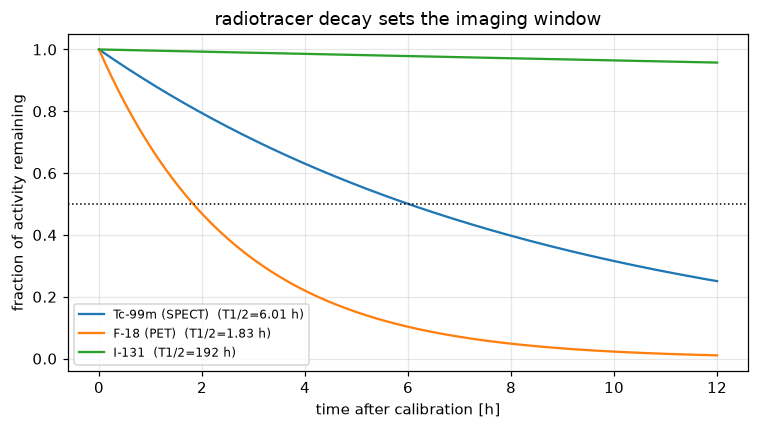

F-18 remaining after 2 h: 0.469


In [2]:
t = np.linspace(0, 12, 300)                            # hours
tracers = {"Tc-99m (SPECT)": 6.01, "F-18 (PET)": 1.83, "I-131": 192.0}

plt.figure(figsize=(7, 4))
for name, half in tracers.items():
    plt.plot(t, 0.5 ** (t / half), label=f"{name}  (T1/2={half:g} h)")
plt.axhline(0.5, color="k", ls=":", lw=1)
plt.xlabel("time after calibration [h]"); plt.ylabel("fraction of activity remaining")
plt.title("radiotracer decay sets the imaging window")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print("F-18 remaining after 2 h:", round(0.5 ** (2 / 1.83), 3))

## 2. Emission tomography = CT reconstruction, but photon-starved

A gamma camera records **projections** of the emitted activity at many angles — exactly a **sinogram**
— and we invert it with **filtered back-projection**, just like CT. The crucial difference: emission
events are **rare** (parts-per-million), so each projection is a **Poisson** count with few photons.
The reconstruction is therefore **noisy and low-resolution** compared to CT.

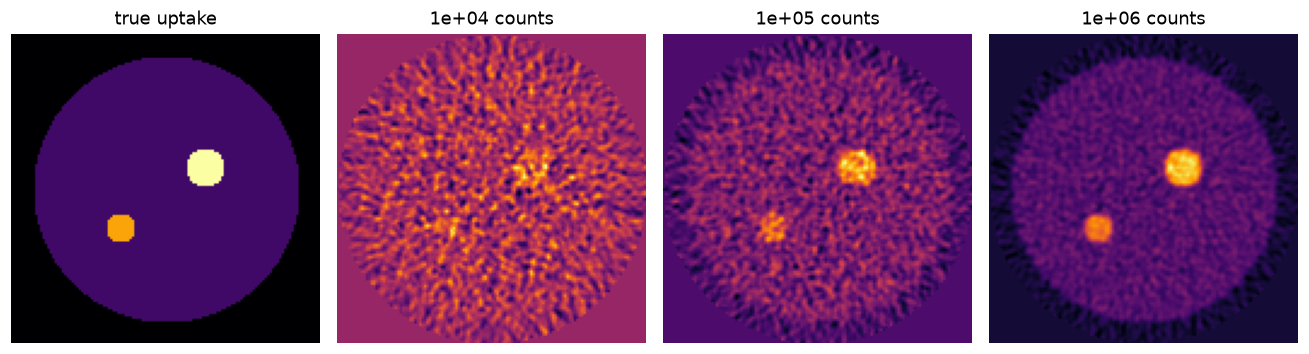

In [3]:
def emission_recon(total_counts):
    expected = sino / sino.sum() * total_counts       # spread the budget over the sinogram
    counts = rng.poisson(expected).astype(float)       # photon counting = Poisson
    return iradon(counts, theta=theta, filter_name="hann", circle=True)

fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
ax[0].imshow(emission, cmap="inferno"); ax[0].set_title("true uptake"); ax[0].axis("off")
for a, c in zip(ax[1:], [1e4, 1e5, 1e6]):
    a.imshow(emission_recon(c), cmap="inferno"); a.set_title(f"{c:.0e} counts"); a.axis("off")
plt.tight_layout(); plt.show()

## 3. Counting statistics: listen longer, see better

For Poisson counts the noise is $\sqrt{N}$, so **signal-to-noise grows as $\sqrt{N}$** — collecting more
counts (a **longer acquisition**, like listening to the MR signal longer for more k-space) steadily
improves the image. This is why nuclear scans take **minutes**, and why resolution stays modest.

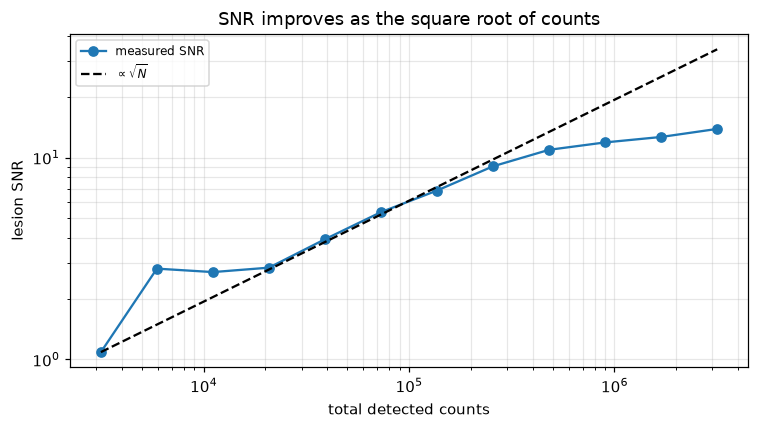

In [4]:
counts_grid = np.logspace(3.5, 6.5, 12)
snr = []
for c in counts_grid:
    rec = emission_recon(c)
    hot = rec[52:58, 76:84].mean()
    bg = rec[20:40, 20:40].std()
    snr.append(hot / (bg + 1e-9))

plt.figure(figsize=(7, 4))
plt.loglog(counts_grid, snr, "o-", label="measured SNR")
plt.loglog(counts_grid, snr[0] * np.sqrt(counts_grid / counts_grid[0]), "k--", label=r"$\propto \sqrt{N}$")
plt.xlabel("total detected counts"); plt.ylabel("lesion SNR")
plt.title("SNR improves as the square root of counts")
plt.legend(fontsize=8); plt.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

## 4. SPECT vs PET

- **SPECT** (Single-Photon Emission CT): the tracer emits **one** gamma (e.g. Tc-99m, 140 keV). An
  **Anger scintillation camera** (Hal Anger, 1950) — a big crystal + photomultipliers — with a
  **collimator** records direction; **two cameras at right angles** rotate, *listen–rotate–listen*, to
  build projections. Each projection is a 2-D plane; the stack is Radon space for a 3-D reconstruction.
- **PET** (Positron Emission Tomography): the tracer emits a **positron** that annihilates with an
  electron into **two 511 keV photons flying 180° apart**. A **ring** of detectors records
  **coincidences**; each pair defines a **line of response (LOR)** through the source — electronic
  collimation, no physical collimator, so higher sensitivity. The LORs are binned into a sinogram and
  reconstructed.

Below, many annihilation LORs from two sources all pass through their origin — their crossing density
localizes the activity.

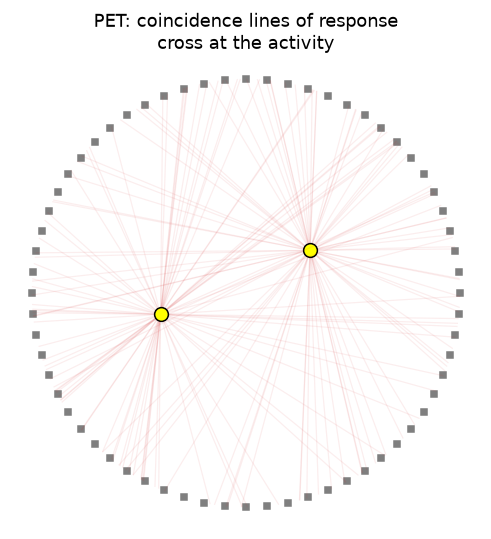

In [5]:
R = 1.0
detector_angles = np.linspace(0, 2 * np.pi, 64, endpoint=False)
sources = [(0.30, 0.20), (-0.40, -0.10)]

def lor_endpoints(px, py, phi):
    dx, dy = np.cos(phi), np.sin(phi)
    b = 2 * (px * dx + py * dy); c = px * px + py * py - R * R
    disc = b * b - 4 * c
    t1 = (-b + np.sqrt(disc)) / 2; t2 = (-b - np.sqrt(disc)) / 2
    return (px + t1 * dx, py + t1 * dy), (px + t2 * dx, py + t2 * dy)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(R * np.cos(detector_angles), R * np.sin(detector_angles), "s", ms=4, color="tab:gray", label="detector ring")
for sx, sy in sources:
    for _ in range(40):
        (x1, y1), (x2, y2) = lor_endpoints(sx, sy, rng.uniform(0, np.pi))
        ax.plot([x1, x2], [y1, y2], color="tab:red", alpha=0.08, lw=0.8)
    ax.plot(sx, sy, "o", color="yellow", mec="k", ms=9)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("PET: coincidence lines of response\ncross at the activity")
plt.tight_layout(); plt.show()

## 5. Fusion: functional activity on structural anatomy

Nuclear images show **function** but little anatomy, so they are **co-registered** (fused) with a
structural **CT or MRI**. The hot spots then have an anatomical address — essential for staging and
**image-guided surgery** (PET/CT and SPECT/CT scanners do this routinely).

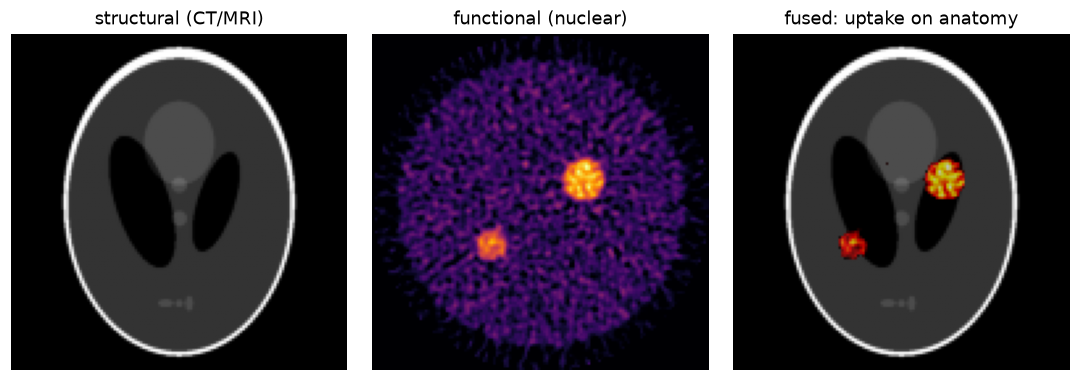

In [6]:
structural = resize(shepp_logan_phantom(), (N, N), anti_aliasing=True)   # stand-in CT/MRI
functional = emission_recon(3e5)
functional = np.clip(functional, 0, None)
overlay = np.ma.masked_less(functional / functional.max(), 0.45)          # show only hot voxels

fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
ax[0].imshow(structural, cmap="gray"); ax[0].set_title("structural (CT/MRI)"); ax[0].axis("off")
ax[1].imshow(functional, cmap="inferno"); ax[1].set_title("functional (nuclear)"); ax[1].axis("off")
ax[2].imshow(structural, cmap="gray")
ax[2].imshow(overlay, cmap="hot", alpha=0.75)
ax[2].set_title("fused: uptake on anatomy"); ax[2].axis("off")
plt.tight_layout(); plt.show()

## Clinical interpretation and practical limits

- In a **myocardial perfusion SPECT** study, viable, perfused myocardium takes up tracer and appears relatively bright; a persistent low-uptake region can indicate scar, while interpretation also depends on stress/rest comparison and acquisition quality. Short-axis slices are often summarized as a **polar map** from apex to base.
- **PET brightness is tracer-dependent**, not simply the inverse of SPECT. With **FDG-PET**, increased glucose use can make tumors and other metabolically active tissue bright; other PET tracers answer different physiologic questions.
- Collecting more counts improves Poisson-limited precision approximately as $\sqrt{N}$, but longer scans increase the opportunity for patient motion. Motion can blur or misregister the reconstructed activity.
- Fusing functional PET/SPECT with anatomical CT/MRI is an **image-registration** problem. Many deformations can make images appear aligned, so registration needs a suitable objective (for example, mutual information) and clinical validation; visual overlap alone does not guarantee a correct mapping.

## Takeaways

| | SPECT | PET |
|---|---|---|
| Emission | single gamma | positron → two 511 keV photons (180°) |
| Tracer | Tc-99m, ~6 h | F-18 FDG, ~110 min |
| Localization | physical **collimator** | **coincidence** (electronic) |
| Detector | rotating **Anger** gamma cameras | fixed detector **ring** |

- Nuclear imaging measures an **active** emission (MRI-like source) but reconstructs with **CT-like**
  methods (projections → Radon → **FBP / algebraic / direct-Fourier**).
- Events are **rare** → **Poisson** counts, so images are **noisy**; **SNR ∝ √counts**, while longer scans can
  increase motion-related error.
- It highlights **tracer-dependent function/metabolism** and is often **fused** with CT/MRI for anatomy.
- For related **radiation dosimetry** (becquerel, gray, sievert, entrance skin dose), see the Week 11 notebook.